# Notebook 2: Merged circRNA–miRNA benchmark + bias audit
This notebook does the first two steps of the plan:
1. **Build** one deduplicated circRNA–miRNA dataset from HMA-GCA D1, D2 and D3, with leak-free evaluation splits and two kinds of negatives.
2. **Audit** with simple baselines: how much does performance drop when the shortcuts (popularity, already-seen RNAs) are removed?

**Splits** (5 folds each): `warm` (random pairs, as in the papers) · `cold_circ` (test circRNAs never seen in training) · `cold_mirna` (test miRNAs unseen) · `cold_both` (both unseen).
**Test negatives** (1:1): `random` (uniform unlabeled pairs, as in the papers) · `degree` (negatives drawn with the same popularity bias as positives, so popularity gives no free signal).
**Features:** only K-mer and CTD. I checked on your files that these are *identical* across D1/D2/D3 for the same RNA (computed from sequence), while Doc2Vec and Role2Vec differ per dataset (trained per dataset / network-based), so they cannot be merged.

**Baselines:** popularity (degree product) · sequence-only gradient boosting · sequence + degree gradient boosting. The last one shows how much a model gains from the degree shortcut.

Outputs go to `./processed/` (keep your raw folder untouched).

In [5]:
import os, re, glob, zipfile, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"]=110
try:
    from IPython.display import display
except Exception:
    display = print

# ---------------- CONFIG ----------------
UPLOADS  = "/mnt/user-data/uploads"    # folder containing combine-dataset.zip
ONLY_ZIP = "combine-dataset.zip"
RAW_DIR  = "/kaggle/input/datasets/jasminsultanashimu/combine-dataset/combine-dataset/hma-gca-dataset"                       # or path to an already-unpacked folder containing dataset1/2/3 (skips unzip)
EXTRACT  = "./extracted"
OUT      = "./processed"
N_FOLDS  = 5
SEED     = 42
RUN_MODELS = True                      # False = build data + popularity audit only (fast)
HGB_ITERS  = 150
# ----------------------------------------
os.makedirs(EXTRACT, exist_ok=True); os.makedirs(OUT, exist_ok=True)

## 1. Load D1, D2, D3 (only the files needed: K-mer, CTD, interaction matrix)

In [6]:
if RAW_DIR is None:
    pat = re.compile(r"hma-gca-dataset/dataset(\d)/((circRNA|miRNA)_(kmer|ctd)_dict\.txt|matrix_[^/]+\.csv)$")
    for z in glob.glob(os.path.join(UPLOADS, "**", "*.zip"), recursive=True):
        if ONLY_ZIP and os.path.basename(z) != ONLY_ZIP: continue
        with zipfile.ZipFile(z) as f:
            for m in f.namelist():
                if pat.search(m): f.extract(m, EXTRACT)
root = RAW_DIR or EXTRACT
dirs = {}
for h in glob.glob(os.path.join(root, "**", "circRNA_kmer_dict.txt"), recursive=True):
    d = os.path.dirname(h); k = re.findall(r"dataset\s*_?(\d)", d.lower())[-1]; dirs[int(k)] = d
assert len(dirs) == 3, f"expected dataset1/2/3, found {dirs}"
print({k: dirs[k] for k in sorted(dirs)})

def read_feats(path):
    ids, rows = [], []
    for l in open(path):
        p = l.strip().split(",")
        if len(p) > 1: ids.append(p[0]); rows.append(np.array(p[1:], dtype=np.float32))
    return ids, np.vstack(rows)

raw = {}
for k, d in sorted(dirs.items()):
    cid, ck = read_feats(f"{d}/circRNA_kmer_dict.txt"); _, cc = read_feats(f"{d}/circRNA_ctd_dict.txt")
    mid, mk = read_feats(f"{d}/miRNA_kmer_dict.txt");   _, mc = read_feats(f"{d}/miRNA_ctd_dict.txt")
    A = pd.read_csv(glob.glob(f"{d}/matrix_*.csv")[0], header=None).values
    assert A.shape == (len(mid), len(cid))
    raw[k] = dict(circ=cid, mi=mid, ck=ck, cc=cc, mk=mk, mc=mc, A=A)
    print(f"D{k}: {len(cid)} circRNAs, {len(mid)} miRNAs, {int(A.sum())} pairs")

{1: '/kaggle/input/datasets/jasminsultanashimu/combine-dataset/combine-dataset/hma-gca-dataset/dataset1', 2: '/kaggle/input/datasets/jasminsultanashimu/combine-dataset/combine-dataset/hma-gca-dataset/dataset2', 3: '/kaggle/input/datasets/jasminsultanashimu/combine-dataset/combine-dataset/hma-gca-dataset/dataset3'}
D1: 2115 circRNAs, 821 miRNAs, 9589 pairs
D2: 2346 circRNAs, 962 miRNAs, 9905 pairs
D3: 3569 circRNAs, 1152 miRNAs, 20208 pairs


## 2. Merge into one dataset
- Nodes = union of IDs. Pairs = union of positives, one row per unique pair, with `in_D1/in_D2/in_D3` flags (so the paper's individual datasets can still be reproduced).
- Features: taken from D3, then D2, then D1 (identical where they overlap, verified below).

In [7]:
circ_ids = sorted(set().union(*[set(r["circ"]) for r in raw.values()]))
mi_ids   = sorted(set().union(*[set(r["mi"])   for r in raw.values()]))
ci = {x:i for i,x in enumerate(circ_ids)}; mj = {x:i for i,x in enumerate(mi_ids)}
nc, nm = len(circ_ids), len(mi_ids)

def build_feat(ids_all, idx, kind):          # kind: ("ck","cc") or ("mk","mc")
    X = np.full((len(ids_all), raw[3][kind[0]].shape[1] + raw[3][kind[1]].shape[1]), np.nan, dtype=np.float32); mism = 0; both = 0
    for k in (1, 2, 3):                        # later datasets overwrite earlier ones -> priority D3 > D2 > D1
        r = raw[k]; ids = r["circ"] if kind[0]=="ck" else r["mi"]; F = np.hstack([r[kind[0]], r[kind[1]]])
        for n_, id_ in enumerate(ids):
            j = idx[id_]
            if not np.isnan(X[j,0]):
                both += 1; mism += (not np.allclose(X[j], F[n_], atol=1e-4))
            X[j] = F[n_]
    return X, mism, both
Xc, mc_, bc_ = build_feat(circ_ids, ci, ("ck","cc")); Xm, mm_, bm_ = build_feat(mi_ids, mj, ("mk","mc"))
print(f"feature consistency across datasets: circRNA mismatches {mc_}/{bc_} overlaps, miRNA mismatches {mm_}/{bm_} overlaps")
assert not np.isnan(Xc).any() and not np.isnan(Xm).any()

rows = {}
for k, r in raw.items():
    for m, c in zip(*np.nonzero(r["A"])):
        key = (mj[r["mi"][m]], ci[r["circ"][c]]); rows.setdefault(key, {1:0,2:0,3:0})[k] = 1
P = pd.DataFrame([(m, c, v[1], v[2], v[3]) for (m, c), v in rows.items()], columns=["mi","circ","in_D1","in_D2","in_D3"]).sort_values(["circ","mi"]).reset_index(drop=True)
A_full = np.zeros((nm, nc), dtype=np.int8); A_full[P.mi, P.circ] = 1
print(f"MERGED: {nc} circRNAs, {nm} miRNAs, {len(P)} unique positive pairs (density {100*len(P)/(nc*nm):.3f}%)")
display(P[["in_D1","in_D2","in_D3"]].value_counts().rename("pairs").to_frame())

pd.Series(circ_ids, name="circRNA").to_csv(f"{OUT}/circ_ids.csv", index_label="idx"); pd.Series(mi_ids, name="miRNA").to_csv(f"{OUT}/mirna_ids.csv", index_label="idx")
P.assign(circ_id=[circ_ids[i] for i in P.circ], mirna_id=[mi_ids[i] for i in P.mi]).to_csv(f"{OUT}/pairs_merged.csv", index=False)
np.savez_compressed(f"{OUT}/seq_features.npz", circ=Xc, mirna=Xm)

feature consistency across datasets: circRNA mismatches 0/4228 overlaps, miRNA mismatches 0/1662 overlaps
MERGED: 3802 circRNAs, 1273 miRNAs, 20771 unique positive pairs (density 0.429%)


,,,pairs
in_D1,in_D2,in_D3,
0,0,1,10866
1,1,1,9342
0,1,0,316
1,1,0,247


## 3. Splits and negatives
For each split and fold, three parts are stored: `train` (positives + 1:1 random negatives from training-eligible nodes), `test_random` and `test_degree` (the same test positives with two different negative sets).
In `degree` negatives, a circRNA/miRNA is drawn with probability proportional to its degree in the full positive graph (restricted to the test-eligible nodes), so negatives are as "popular" as positives. No negative ever coincides with a known positive, and train/test negatives are disjoint.

In [8]:
rng = np.random.default_rng(SEED)
fc = rng.permutation(np.arange(nc) % N_FOLDS); fm = rng.permutation(np.arange(nm) % N_FOLDS)   # fold id per node (for cold splits)
deg_c = A_full.sum(0).astype(float); deg_m = A_full.sum(1).astype(float)
pos = P[["circ","mi"]].values                                                                        # (n,2): circ idx, mi idx
SPLITS = ["warm","cold_circ","cold_mirna","cold_both"]

def draw_negs(n, c_pool, m_pool, rng, degree, forbid):
    pc = pm = None
    if degree:
        pc = deg_c[c_pool] + 1e-9; pc = pc/pc.sum(); pm = deg_m[m_pool] + 1e-9; pm = pm/pm.sum()
    out, seen = [], set()
    for _ in range(1000):
        if len(out) >= n: break
        k = (n - len(out)) * 3
        c = rng.choice(c_pool, k, p=pc); m = rng.choice(m_pool, k, p=pm)
        for a, b in zip(c, m):
            key = int(a) * nm + int(b)
            if A_full[b, a] == 0 and key not in seen and key not in forbid:
                seen.add(key); out.append((a, b))
                if len(out) >= n: break
    assert len(out) == n, "could not sample enough negatives"
    return np.array(out)

def make_fold(split, k):
    allc, allm = np.arange(nc), np.arange(nm)
    if split == "warm":
        te = KFold(N_FOLDS, shuffle=True, random_state=SEED).split(pos); te = list(te)[k][1]
        tmask = np.zeros(len(pos), bool); tmask[te] = True
        c_te, m_te, c_tr, m_tr = allc, allm, allc, allm
        test_pos, train_pos = pos[tmask], pos[~tmask]
    else:
        ct = allc[fc == k] if split in ("cold_circ","cold_both") else allc
        mt = allm[fm == k] if split in ("cold_mirna","cold_both") else allm
        ctr = allc[fc != k] if split in ("cold_circ","cold_both") else allc
        mtr = allm[fm != k] if split in ("cold_mirna","cold_both") else allm
        in_te = np.isin(pos[:,0], ct) & np.isin(pos[:,1], mt); in_tr = np.isin(pos[:,0], ctr) & np.isin(pos[:,1], mtr)
        test_pos, train_pos = pos[in_te], pos[in_tr]; c_te, m_te, c_tr, m_tr = ct, mt, ctr, mtr
    n_te, n_tr = len(test_pos), len(train_pos)
    r = np.random.default_rng(SEED + 1000*SPLITS.index(split) + k)
    tr_rand = draw_negs(n_te, c_te, m_te, r, False, set()); tr_deg = draw_negs(n_te, c_te, m_te, r, True, {int(a)*nm+int(b) for a,b in tr_rand})
    forbid = {int(a)*nm+int(b) for a,b in np.vstack([tr_rand, tr_deg])}
    train_neg = draw_negs(n_tr, c_tr, m_tr, r, False, forbid)
    parts = []
    for name, p_, n_ in [("train", train_pos, train_neg), ("test_random", test_pos, tr_rand), ("test_degree", test_pos, tr_deg)]:
        parts.append(pd.DataFrame({"split":split,"fold":k,"part":name,"circ":np.r_[p_[:,0], n_[:,0]],"mi":np.r_[p_[:,1], n_[:,1]],"label":np.r_[np.ones(len(p_)),np.zeros(len(n_))].astype(int)}))
    return pd.concat(parts, ignore_index=True), (c_te, m_te, c_tr, m_tr)

t0=time.time(); frames=[]; checks=[]
for split in SPLITS:
    for k in range(N_FOLDS):
        df, (c_te, m_te, c_tr, m_tr) = make_fold(split, k); frames.append(df)
        tr, tp = df[df.part=="train"], df[df.part=="test_random"]
        trp = {(a,b) for a,b in tr[tr.label==1][["circ","mi"]].values}; tep = {(a,b) for a,b in tp[tp.label==1][["circ","mi"]].values}
        neg_all = df[df.label==0]
        checks.append(dict(split=split, fold=k, train_pos=len(trp), test_pos=len(tep),
            pos_overlap=len(trp & tep),
            neg_is_known_positive=int(A_full[neg_all.mi.values, neg_all.circ.values].sum()),
            train_test_neg_overlap=len(set(map(tuple, tr[tr.label==0][["circ","mi"]].values)) & set(map(tuple, df[(df.part!="train")&(df.label==0)][["circ","mi"]].values))),
            test_circ_seen_in_train=int(len(set(tp.circ) & set(tr.circ))) if split in ("cold_circ","cold_both") else None,
            test_mirna_seen_in_train=int(len(set(tp.mi) & set(tr.mi))) if split in ("cold_mirna","cold_both") else None))
S = pd.concat(frames, ignore_index=True); CK = pd.DataFrame(checks)
S.to_csv(f"{OUT}/splits.csv.gz", index=False); CK.to_csv(f"{OUT}/leakage_checks.csv", index=False)
print(f"built {len(S):,} rows in {time.time()-t0:.0f}s")
display(CK.groupby("split")[["train_pos","test_pos","pos_overlap","neg_is_known_positive","train_test_neg_overlap","test_circ_seen_in_train","test_mirna_seen_in_train"]].agg(["mean","max"]).round(1))
bad = CK[["pos_overlap","neg_is_known_positive","train_test_neg_overlap"]].sum().sum() + CK.test_circ_seen_in_train.fillna(0).sum() + CK.test_mirna_seen_in_train.fillna(0).sum()
print("LEAKAGE CHECK:", "PASSED (all overlaps are 0)" if bad == 0 else f"FAILED, total violations = {bad}")

built 897,312 rows in 6s


train_pos        test_pos       pos_overlap      \
                mean    max     mean   max        mean max   
split                                                        
cold_both    13293.6  13700    831.0   960         0.0   0   
cold_circ    16616.8  16908   4154.2  4539         0.0   0   
cold_mirna   16616.8  17208   4154.2  4419         0.0   0   
warm         16616.8  16617   4154.2  4155         0.0   0   

           neg_is_known_positive     train_test_neg_overlap      \
                            mean max                   mean max   
split                                                             
cold_both                    0.0   0                    0.0   0   
cold_circ                    0.0   0                    0.0   0   
cold_mirna                   0.0   0                    0.0   0   
warm                         0.0   0                    0.0   0   

           test_circ_seen_in_train      test_mirna_seen_in_train       
                              mean  max                     mean  max  
split                                                                  
cold_both                      0.0  0.0                      0.0  0.0  
cold_circ                      0.0  0.0                      NaN  NaN  
cold_mirna                     NaN  NaN                      0.0  0.0  
warm                           NaN  NaN                      NaN  NaN

LEAKAGE CHECK: PASSED (all overlaps are 0)


## 4. How hard is each setting? (test-set composition)
Sizes of the test sets, and how popular the test positives are compared with the test negatives (mean degree). In `degree` negatives the two should be close.

In [9]:
T = S[S.part.isin(["test_random","test_degree"])].copy()
T["deg_c"] = deg_c[T.circ.values]; T["deg_m"] = deg_m[T.mi.values]
comp = T.groupby(["split","part","label"]).agg(n_total_over_folds=("circ","size"), mean_circ_deg=("deg_c","mean"), mean_mirna_deg=("deg_m","mean")).round(2)
display(comp.loc[(slice(None),slice(None),slice(None)),:].unstack("label"))

n_total_over_folds        mean_circ_deg         \
label                                   0      1             0      1   
split      part                                                         
cold_both  test_degree               4155   4155         15.12  16.17   
           test_random               4155   4155          5.53  16.17   
cold_circ  test_degree              20771  20771         15.05  16.09   
           test_random              20771  20771          5.36  16.09   
cold_mirna test_degree              20771  20771         15.13  16.09   
           test_random              20771  20771          5.61  16.09   
warm       test_degree              20771  20771         15.45  16.09   
           test_random              20771  20771          5.51  16.09   

                       mean_mirna_deg         
label                               0      1  
split      part                               
cold_both  test_degree          87.38  94.82  
           test_random          15.81  94.82  
cold_circ  test_degree          88.72  95.98  
           test_random          16.22  95.98  
cold_mirna test_degree          87.22  95.98  
           test_random          16.26  95.98  
warm       test_degree          90.89  95.98  
           test_random          15.74  95.98

## 5. Baselines and audit
For every split × fold × negative type:
- **popularity**: log(1+degree of circRNA) + log(1+degree of miRNA), degrees from the *training* positives only (unseen nodes get 0, so in a cold split only the seen side contributes)
- **seq_only**: gradient boosting on [circRNA K-mer+CTD, miRNA K-mer+CTD]
- **seq+degree**: the same plus log(1+training degree) of both nodes. Training degrees include each training edge itself, as in the HMA-GCA code, which is what makes the shortcut learnable.

In [10]:
def feats(df, dc, dm, with_deg):
    X = np.hstack([Xc[df.circ.values], Xm[df.mi.values]])
    return np.hstack([X, np.log1p(dc[df.circ.values])[:,None], np.log1p(dm[df.mi.values])[:,None]]) if with_deg else X

res = []; t0 = time.time()
for split in SPLITS:
    for k in range(N_FOLDS):
        d = S[(S.split==split)&(S.fold==k)]; tr = d[d.part=="train"]
        tp = tr[tr.label==1]; dc = np.bincount(tp.circ, minlength=nc).astype(float); dm = np.bincount(tp.mi, minlength=nm).astype(float)
        scorers = {"popularity": lambda df: np.log1p(dc[df.circ.values]) + np.log1p(dm[df.mi.values])}
        if RUN_MODELS:
            for name, wd in [("seq_only", False), ("seq+degree", True)]:
                clf = HistGradientBoostingClassifier(max_iter=HGB_ITERS, learning_rate=0.1, random_state=SEED).fit(feats(tr, dc, dm, wd), tr.label.values)
                scorers[name] = (lambda c_, wd_: (lambda df: c_.predict_proba(feats(df, dc, dm, wd_))[:,1]))(clf, wd)
        for neg in ["random","degree"]:
            te = d[d.part==f"test_{neg}"]
            for name, fn in scorers.items():
                s_ = fn(te); res.append(dict(split=split, fold=k, negatives=neg, model=name, AUC=roc_auc_score(te.label, s_), AUPR=average_precision_score(te.label, s_)))
    print(split, "done", f"{time.time()-t0:.0f}s")
R = pd.DataFrame(res); R.to_csv(f"{OUT}/audit_results_per_fold.csv", index=False)
Rm = R.groupby(["model","split","negatives"])[["AUC","AUPR"]].agg(["mean","std"]).round(3); Rm.to_csv(f"{OUT}/audit_results_summary.csv"); display(Rm)

warm done 193s
cold_circ done 389s
cold_mirna done 582s
cold_both done 746s


AUC          AUPR       
                                  mean    std   mean    std
model      split      negatives                            
popularity cold_both  degree     0.500  0.000  0.500  0.000
                      random     0.500  0.000  0.500  0.000
           cold_circ  degree     0.517  0.007  0.518  0.007
                      random     0.853  0.004  0.848  0.006
           cold_mirna degree     0.488  0.004  0.502  0.003
                      random     0.730  0.006  0.731  0.007
           warm       degree     0.494  0.006  0.487  0.004
                      random     0.893  0.002  0.895  0.002
seq+degree cold_both  degree     0.688  0.040  0.660  0.033
                      random     0.676  0.040  0.629  0.038
           cold_circ  degree     0.700  0.016  0.684  0.020
                      random     0.911  0.004  0.912  0.006
           cold_mirna degree     0.596  0.031  0.577  0.022
                      random     0.706  0.021  0.705  0.014
           warm       degree     0.673  0.006  0.667  0.010
                      random     0.900  0.003  0.923  0.003
seq_only   cold_both  degree     0.691  0.024  0.653  0.023
                      random     0.873  0.017  0.869  0.023
           cold_circ  degree     0.792  0.007  0.763  0.015
                      random     0.955  0.002  0.957  0.002
           cold_mirna degree     0.692  0.019  0.658  0.018
                      random     0.881  0.008  0.876  0.010
           warm       degree     0.783  0.003  0.748  0.006
                      random     0.960  0.001  0.959  0.002

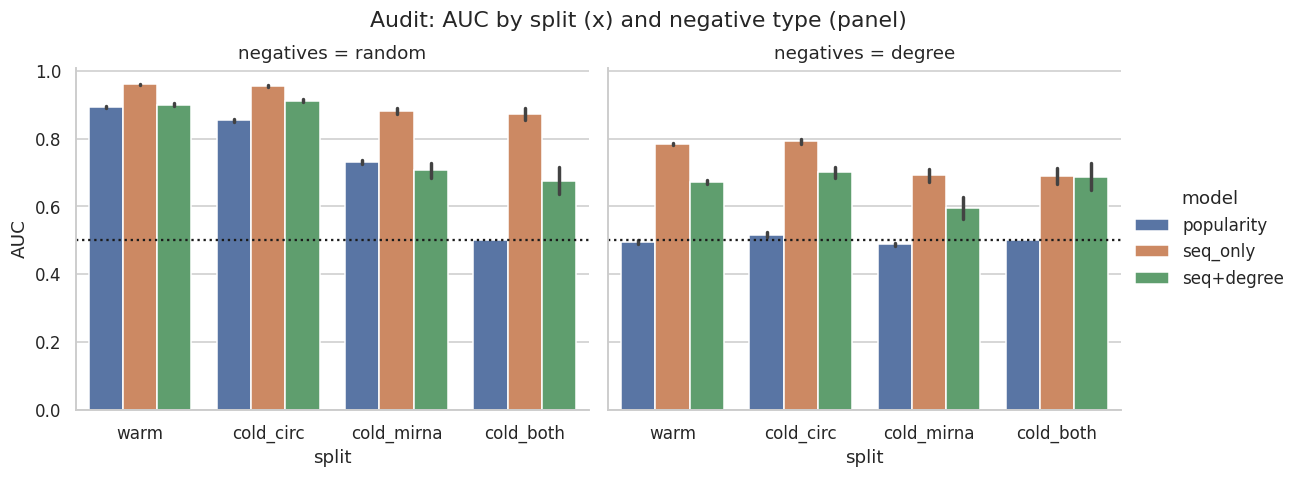

,warm+random (paper-style),cold_both+degree (hardest),drop
model,,,
popularity,0.893,0.500,0.393
seq+degree,0.900,0.688,0.212
seq_only,0.960,0.691,0.269


In [11]:
order = ["popularity","seq_only","seq+degree"] if RUN_MODELS else ["popularity"]
g = sns.catplot(data=R, x="split", y="AUC", hue="model", hue_order=order, col="negatives", kind="bar", order=SPLITS, errorbar="sd", height=4.2, aspect=1.25)
for ax in g.axes.ravel(): ax.axhline(0.5, color="k", ls=":")
g.fig.suptitle("Audit: AUC by split (x) and negative type (panel)", y=1.03); plt.savefig(f"{OUT}/fig_audit_auc.png", bbox_inches="tight"); plt.show()

M = R.groupby(["model","split","negatives"]).AUC.mean().unstack(["negatives"])
drop = pd.DataFrame({"warm+random (paper-style)": M.xs("warm", level="split")["random"], "cold_both+degree (hardest)": M.xs("cold_both", level="split")["degree"]}); drop["drop"] = drop.iloc[:,0]-drop.iloc[:,1]
display(drop.round(3))

### How to read the results
| Observation | Meaning |
|---|---|
| `popularity` AUC high on `warm+random` | popularity alone explains a large part of the paper-style score |
| `popularity` ≈ 0.5 on `degree` and on cold splits | the shortcut is removed by the benchmark |
| `seq+degree` ≫ `seq_only` on `warm+random` | models can exploit degree; the gap is the size of the shortcut |
| `seq_only` falls sharply on cold splits | sequence features alone generalise poorly to unseen RNAs; this is the room for a better model |
| `seq_only` holds up on cold splits | sequence signal is real, and the method paper can build on it |

**Next:** put HMA-GCA (and its better variants) on exactly these stored splits (`processed/splits.csv.gz`), then add the popularity-debiased model.

In [13]:
import shutil, os
from IPython.display import FileLink, display

os.chdir("/kaggle/working")   # make sure relative paths match OUT="./processed"
print(sorted(os.listdir("processed")))   # check that all 9 files are there

shutil.make_archive("processed_results", "zip", "/kaggle/working", "processed")
print(f"{os.path.getsize('processed_results.zip')/1e6:.1f} MB")
display(FileLink("processed_results.zip"))

['audit_results_per_fold.csv', 'audit_results_summary.csv', 'circ_ids.csv', 'fig_audit_auc.png', 'leakage_checks.csv', 'mirna_ids.csv', 'pairs_merged.csv', 'seq_features.npz', 'splits.csv.gz']
6.6 MB


/kaggle/working/processed_results.zip